## Ryan Campbell, Section 002

### Context
For my project, I want to do something with sports statistics. I found two datasets online, one for baseball and one for hockey.
I wanted to do something with the hockey data set and since hockey doesn't have a WAR stat I wanted to make my own.
In baseball, WAR stands for wins above replacement, and it is used to show how valuable a certain player is to their team.
If a player has a WAR of 40, that means that compared to the league average, he provides 40 wins worth of value in hitting, defence, etc.
I wanted to make one for hockey since the aspects of the game are similar to baseball, with one player needing to play offense and defense. Obviously there might be some bias in my data set since better players usually play for better teams, so I wanted statistics that value a players individual output rather than team results.

The research question I am asking is, "Can we calculate a single statistic for hockey players that values offense and defense of a specific player, and compares their output to the league average, showing how valuable they are to their team?"

I found my dataset on moneypuck.com, which was a csv file containing every player's statistics from the 2023-2024 season. It contains everything about each player from the previous season. This includes basic statistics like time on ice, goals, shots, etc, but it also contains things like expected goals, corsi (which is a score from 0-1 on how a player played in a certain game), etc. One limitation is that the dataset does not include any team related data, like a teams record, their goal differential, or top players. This means that I can't compare teams to eachother, I can only compare players.

"The data below is free to use for non-commercial purposes and by journalists for ad-hoc use. Please clearly credit MoneyPuck.com in all cases where you are showing anything using our data as an input. For other purposes please inquire by messaging moneypuck.com@gmail.com."

My goal is to filter the data first, only highlighting the statistics I want. Then, I run it through a mathematical model that takes in all of the variables for one player and outputs a single number. Once I have an idea of this, I would then like to compare positional value and see if there is a correlation between a players individual success and overall team success.


In [860]:
import pandas as pd
import numpy as np
df = pd.read_csv("skaters.csv")

In [956]:
df_filtered = df[df['games_played'] > 50].copy()
df_filtered['TOI_minutes'] = df_filtered['icetime']  / 60

df_filtered = df_filtered[df_filtered['TOI_minutes'] >= 1500]
df_filtered = df_filtered[df_filtered['situation'] == 'all']
df_filtered = df_filtered[df_filtered['I_F_points'] >= 25]

# Calculate per-60 stats
df_filtered['Goals_per_60'] = (df_filtered['I_F_goals'] / df_filtered['TOI_minutes']) * 60
df_filtered['Assists_per_60'] = ((df_filtered['I_F_primaryAssists'] + df_filtered['I_F_secondaryAssists']) / df_filtered['TOI_minutes']) * 60
df_filtered['xG_per_60'] = (df_filtered['I_F_xGoals'] / df_filtered['TOI_minutes']) * 60
df_filtered['Blocked_per_60'] = (df_filtered['shotsBlockedByPlayer'] / df_filtered['TOI_minutes']) * 60
df_filtered['xGA_per_60'] = (df_filtered['OnIce_A_xGoals'] / df_filtered['TOI_minutes']) * 60
df_filtered['Takeaways_per_60'] = (df_filtered['I_F_takeaways'] / df_filtered['TOI_minutes']) * 60
df_filtered['Giveaways_per_60'] = (df_filtered['I_F_giveaways'] / df_filtered['TOI_minutes']) * 60
df_filtered['Shots_per_60'] = (df_filtered['I_F_shotsOnGoal'] / df_filtered['TOI_minutes']) * 60
df_filtered['PenaltiesTaken_per_60'] = (df_filtered['penalties'] / df_filtered['TOI_minutes']) * 60
df_filtered['PenaltyMinutes_per_60'] = (df_filtered['I_F_penalityMinutes'] / df_filtered['TOI_minutes']) * 60
df_filtered['PenaltiesDrawn_per_60'] = (df_filtered['penaltiesDrawn'] / df_filtered['TOI_minutes']) * 60
df_filtered['Corsi_for_per_60'] = (df_filtered['onIce_corsiPercentage']) * 60
df_filtered['Fenwick_for_per_60'] = (df_filtered['onIce_fenwickPercentage']) * 60
df_filtered['DZone_Giveaways_per_60'] = (df_filtered['I_F_dZoneGiveaways'] /df_filtered['TOI_minutes']) * 60
df_filtered['HDg_per_60'] = (df_filtered['I_F_highDangerGoals'] /df_filtered['TOI_minutes']) * 60
df_filtered['HD_Finishing_per_60'] = (((df_filtered['I_F_highDangerxGoals']) /
                                          df_filtered['I_F_highDangerShots'].replace(0, np.nan))) * 60

replacement_avg = df_filtered.mean(numeric_only=True)

# Offensive WAR Calculation
df_filtered['Offensive_WAR'] = (
    0.3 * (df_filtered['xG_per_60'] - replacement_avg['xG_per_60']) + 
    0.4 * (df_filtered['Goals_per_60'] - replacement_avg['Goals_per_60']) +
    1.4 * (df_filtered['Assists_per_60'] - replacement_avg['Assists_per_60']) + 
    0.7 * (df_filtered['PenaltiesDrawn_per_60'] - replacement_avg['PenaltiesDrawn_per_60']) +
    0.8 * (df_filtered['HDg_per_60'] - replacement_avg['HDg_per_60']) + 
    0.6 * (df_filtered['Shots_per_60'] - replacement_avg['Shots_per_60']) + 
    0.8 * (df_filtered['Corsi_for_per_60'] - replacement_avg['Corsi_for_per_60']) + 
    0.8 * (df_filtered['HD_Finishing_per_60'] - replacement_avg['HD_Finishing_per_60']) +
    0.6 * (df_filtered['Fenwick_for_per_60'] - replacement_avg['Fenwick_for_per_60']) -
    0.5 * (df_filtered['PenaltiesTaken_per_60'] - replacement_avg['PenaltiesTaken_per_60'])
    )

# Defensive WAR Calculation
df_filtered['Defensive_WAR'] = (
    (df_filtered['Blocked_per_60'] - replacement_avg['Blocked_per_60']) +
    ((replacement_avg['xGA_per_60'] - df_filtered['xGA_per_60'])*2) +
    (((df_filtered['Takeaways_per_60'] - replacement_avg['Takeaways_per_60']) - (df_filtered['Giveaways_per_60'] - replacement_avg['Giveaways_per_60']))*2)+
    (replacement_avg['PenaltyMinutes_per_60'] - df_filtered['PenaltyMinutes_per_60']) +
    (replacement_avg['DZone_Giveaways_per_60'] - df_filtered['DZone_Giveaways_per_60']))   


# Calculate total WAR
df_filtered['Total_WAR'] = df_filtered['Offensive_WAR'] + df_filtered['Defensive_WAR']

# Sort players by updated WAR
df_sorted = df_filtered[['name', 'HDg_per_60']].sort_values(by='HDg_per_60', ascending=False)
df_sorted.head(10)

,name,HDg_per_60
186,Sam Reinhart,0.973217
741,Zach Hyman,0.846136
4096,Kirill Kaprizov,0.778611
2741,Chris Kreider,0.740140
71,Sidney Crosby,0.728546
3126,Frank Vatrano,0.717958
1476,Brock Boeser,0.716759
3091,Auston Matthews,0.671266
4036,Filip Forsberg,0.657958
3096,Seth Jarvis,0.632099


/var/folders/q7/bpr_nhqj7vqcptgby42m2btr0000gn/T/ipykernel_43745/2308218535.py:20: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='team_pos', y='Total_WAR', data=best_players, palette=palette)


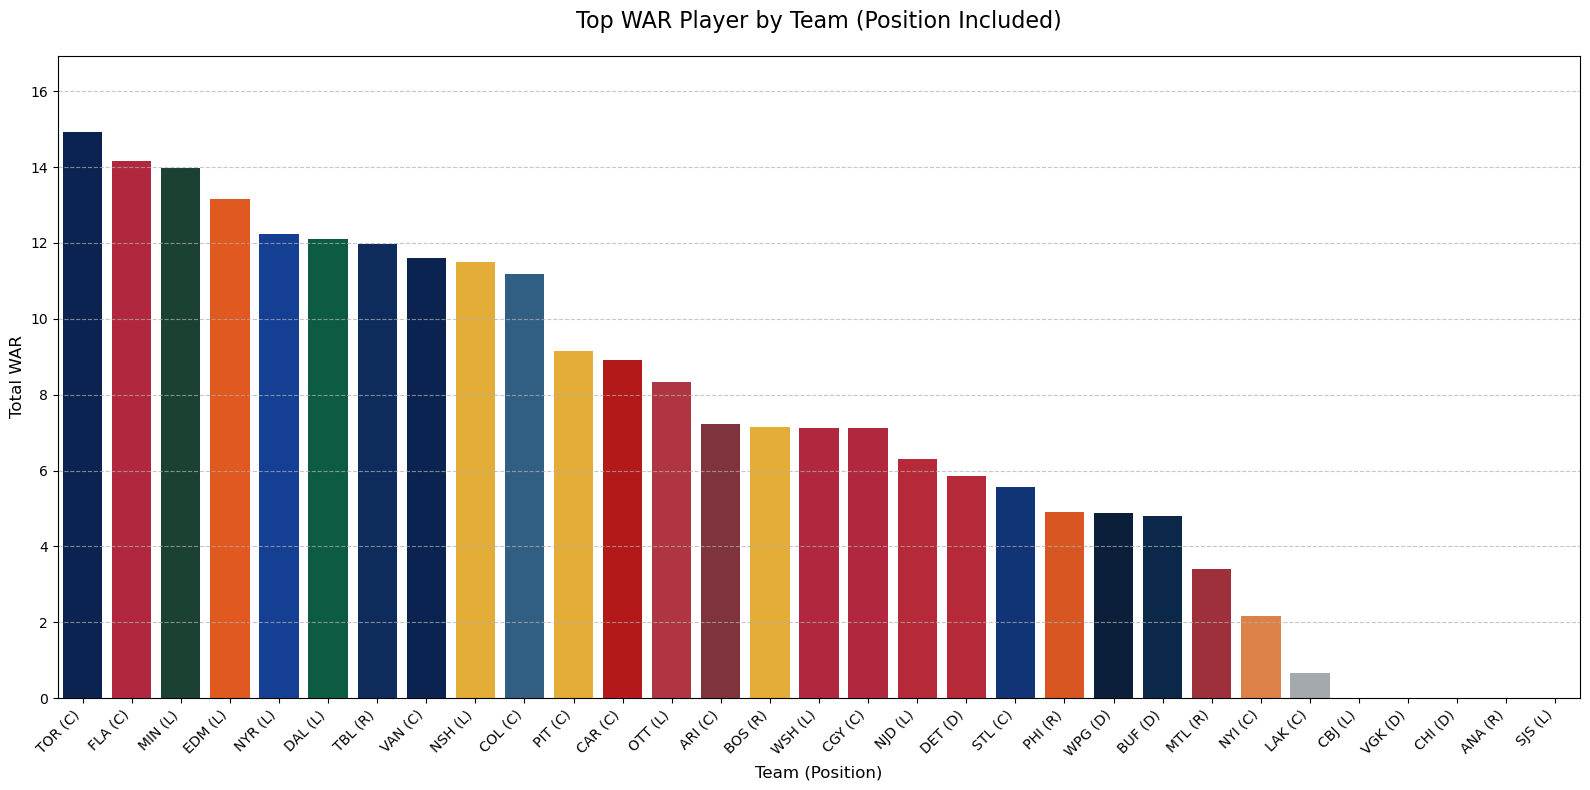

In [958]:
# Top WAR player per team
best_players = df_filtered.sort_values('Total_WAR', ascending=False).groupby('team').head(1).reset_index(drop=True)
best_players['team_pos'] = best_players['team'] + ' (' + best_players['position'] + ')'

# Color palette based on team
team_colors = {
    'ANA': '#B5985A', 'ARI': '#8C2633', 'BOS': '#FFB81C', 'BUF': '#002654',
    'CGY': '#C8102E', 'CAR': '#CC0000', 'CHI': '#CF0A2C', 'COL': '#236192',
    'CBJ': '#002654', 'DAL': '#006847', 'DET': '#CE1126', 'EDM': '#FF4C00',
    'FLA': '#C8102E', 'LAK': '#A2AAAD', 'MIN': '#154734', 'MTL': '#AF1E2D',
    'NSH': '#FFB81C', 'NJD': '#CE1126', 'NYI': '#F47D30', 'NYR': '#0038A8',
    'OTT': '#C52032', 'PHI': '#F74902', 'PIT': '#FFB81C', 'SJS': '#006D75',
    'SEA': '#99D9D9', 'STL': '#002F87', 'TBL': '#002868', 'TOR': '#00205B',
    'VAN': '#001F5B', 'VGK': '#B4975A', 'WSH': '#C8102E', 'WPG': '#041E42'
}
palette = [team_colors.get(team, '#333333') for team in best_players['team']]

# Plot
plt.figure(figsize=(16, 8))
sns.barplot(x='team_pos', y='Total_WAR', data=best_players, palette=palette)

plt.ylim(0, best_players['Total_WAR'].max() + 2)
plt.title("Top WAR Player by Team (Position Included)", fontsize=16, pad=20)
plt.xlabel("Team (Position)", fontsize=12)
plt.ylabel("Total WAR", fontsize=12)
plt.xticks(rotation=45, ha='right')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()


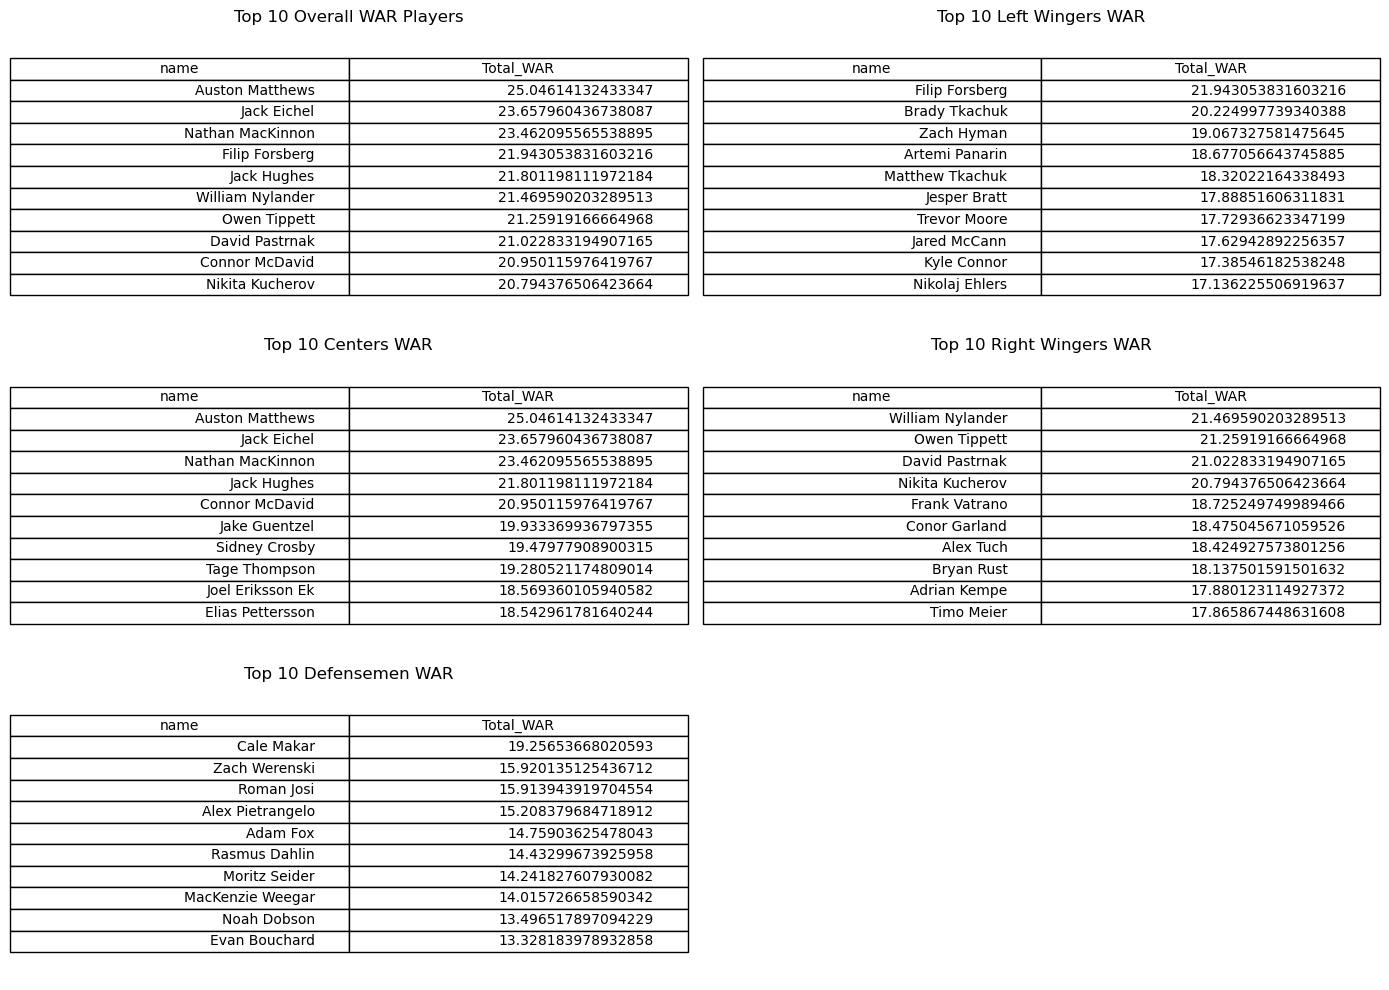

In [766]:
import matplotlib.pyplot as plt
import pandas as pd

df_sorted = df_filtered[['name', 'Total_WAR']].sort_values(by='Total_WAR', ascending=False)

df_L = df_filtered[df_filtered['position'] == 'L'][['name', 'Total_WAR']].sort_values(by='Total_WAR', ascending=False)
df_C = df_filtered[df_filtered['position'] == 'C'][['name', 'Total_WAR']].sort_values(by='Total_WAR', ascending=False)
df_R = df_filtered[df_filtered['position'] == 'R'][['name', 'Total_WAR']].sort_values(by='Total_WAR', ascending=False)
df_D = df_filtered[df_filtered['position'] == 'D'][['name', 'Total_WAR']].sort_values(by='Total_WAR', ascending=False)


fig, axs = plt.subplots(3, 2, figsize=(14, 10))
axs = axs.flatten()

axs[0].axis('off')
axs[0].table(cellText=df_sorted.head(10).values, colLabels=df_sorted.columns, loc='center')
axs[0].set_title('Top 10 Overall WAR Players', fontsize=12)

axs[1].axis('off')
axs[1].table(cellText=df_L.head(10).values, colLabels=df_L.columns, loc='center')
axs[1].set_title('Top 10 Left Wingers WAR', fontsize=12)

axs[2].axis('off')
axs[2].table(cellText=df_C.head(10).values, colLabels=df_C.columns, loc='center')
axs[2].set_title('Top 10 Centers WAR', fontsize=12)

axs[3].axis('off')
axs[3].table(cellText=df_R.head(10).values, colLabels=df_R.columns, loc='center')
axs[3].set_title('Top 10 Right Wingers WAR', fontsize=12)

axs[4].axis('off')
axs[4].table(cellText=df_D.head(10).values, colLabels=df_D.columns, loc='center')
axs[4].set_title('Top 10 Defensemen WAR', fontsize=12)

axs[5].axis('off')
plt.tight_layout()
plt.show()


In [768]:
from scipy.stats import percentileofscore
df_filtered['Off_WAR_percentile'] = df_filtered['Offensive_WAR'].rank(pct=True) * 100
df_filtered['Def_WAR_percentile'] = df_filtered['Defensive_WAR'].rank(pct=True) * 100
df_filtered['xG_percentile'] = df_filtered['xG_per_60'].rank(pct=True) * 100

def get_player_scorecard_df(player_name):
    player_row = df_filtered[df_filtered['name'] == player_name]
    
    if player_row.empty:
        print(f"Player '{player_name}' not found.")
        return None
    
    scorecard = {
    'Player': player_name,
    'Offensive WAR Percentile': f"{round(player_row['Off_WAR_percentile'].values[0], 2)}%",
    'Defensive WAR Percentile': f"{round(player_row['Def_WAR_percentile'].values[0], 2)}%",
    'xG per 60 Percentile': f"{round(player_row['xG_percentile'].values[0], 2)}%",
    'Total WAR': round(player_row['Total_WAR'].values[0], 2)
}
    return pd.DataFrame([scorecard])
player_input = input("Enter a player name: ")
display(get_player_scorecard_df(player_input))

Enter a player name:  Auston Matthews


,Player,Offensive WAR Percentile,Defensive WAR Percentile,xG per 60 Percentile,Total WAR
0,Auston Matthews,97.73%,94.5%,99.68%,25.05


In [906]:

print(list(df.columns)) # Returns a list of column names

['playerId', 'season', 'name', 'team', 'position', 'situation', 'games_played', 'icetime', 'shifts', 'gameScore', 'onIce_xGoalsPercentage', 'offIce_xGoalsPercentage', 'onIce_corsiPercentage', 'offIce_corsiPercentage', 'onIce_fenwickPercentage', 'offIce_fenwickPercentage', 'iceTimeRank', 'I_F_xOnGoal', 'I_F_xGoals', 'I_F_xRebounds', 'I_F_xFreeze', 'I_F_xPlayStopped', 'I_F_xPlayContinuedInZone', 'I_F_xPlayContinuedOutsideZone', 'I_F_flurryAdjustedxGoals', 'I_F_scoreVenueAdjustedxGoals', 'I_F_flurryScoreVenueAdjustedxGoals', 'I_F_primaryAssists', 'I_F_secondaryAssists', 'I_F_shotsOnGoal', 'I_F_missedShots', 'I_F_blockedShotAttempts', 'I_F_shotAttempts', 'I_F_points', 'I_F_goals', 'I_F_rebounds', 'I_F_reboundGoals', 'I_F_freeze', 'I_F_playStopped', 'I_F_playContinuedInZone', 'I_F_playContinuedOutsideZone', 'I_F_savedShotsOnGoal', 'I_F_savedUnblockedShotAttempts', 'penalties', 'I_F_penalityMinutes', 'I_F_faceOffsWon', 'I_F_hits', 'I_F_takeaways', 'I_F_giveaways', 'I_F_lowDangerShots', 'I_F_